In [1]:
# Decision Tree — Bayesian Optimization + 10-fold CV + Test Eval + Plots
import os, platform
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve, average_precision_score
)
from sklearn.preprocessing import label_binarize
import optuna
import joblib

/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ================== CONFIG ==================
CSV_PATH = r"/mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/without timing/full sim results.csv"
TARGET_COL = "isUnderAttack" 
RANDOM_STATE = 42 
N_TRIALS = 60  
TEST_SIZE = 0.25 
CV_FOLDS = 10 
OUT_DIR = "best_model_trained_after_parameter_tuning" 
os.makedirs(OUT_DIR, exist_ok=True)

#TARGET_COL    = "isUnderAttack"
RANDOM_STATE  = 42
N_TRIALS      = 60                
TEST_SIZE     = 0.25
CV_FOLDS      = 10
OUT_DIR       = "best_model_trained_after_parameter_tuning"
os.makedirs(OUT_DIR, exist_ok=True)
# ============================================

def windows_to_wsl_path(win_path: str) -> str:
    try:
        is_wsl = ("microsoft" in platform.release().lower()) or ("microsoft" in platform.version().lower())
    except Exception:
        is_wsl = False
    if not is_wsl:
        return win_path
    p = Path(win_path)
    if str(p).startswith("/"):
        return str(p)
    drive = p.drive.replace(":", "").lower()
    rest = str(p).replace(p.drive, "").replace("\\", "/")
    return f"/mnt/{drive}{rest}"

In [3]:
# ---------- Load data ----------
TRAIN_CSV = windows_to_wsl_path(CSV_PATH)
#TEST_CSV = windows_to_wsl_path(TEST_CSV)
df_train = pd.read_csv(TRAIN_CSV)
#df_test  = pd.read_csv(TEST_CSV)

if TARGET_COL not in df_train.columns:
    raise ValueError(f"TARGET_COL '{TARGET_COL}' not found. Columns: {list(df.columns)}")

X = df_train.drop(columns=[TARGET_COL]).values
y = df_train[TARGET_COL].values
classes = np.unique(y)

print(f"[INFO] Loaded {X.shape[0]:,} rows × {X.shape[1]} features")
print(f"[INFO] Class counts:", dict(zip(*np.unique(y, return_counts=True))))

[INFO] Loaded 58,025 rows × 10 features
[INFO] Class counts: {0: 25773, 1: 12981, 2: 12959, 3: 6312}


In [4]:

skf10 = StratifiedKFold(n_splits=CV_FOLDS, shuffle=False)


In [5]:
# ---------- Parameter pool (explicit) ----------
PARAM_POOL = {
    "criterion": ["gini", "entropy", "log_loss"],
    "splitter": ["best", "random"],
    "max_depth": [None, 20, 40, 60, 100, 150, 200],
    "min_samples_split": [2, 5, 10, 20, 50],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": [None, "sqrt", "log2"],    
    "class_weight": [None, "balanced"],        
    "ccp_alpha": [0.0, 1e-4, 5e-4, 1e-3],      
}
print("\n[PARAMETER POOL]")
for k, v in PARAM_POOL.items():
    print(f"  - {k}: {v}")


[PARAMETER POOL]
  - criterion: ['gini', 'entropy', 'log_loss']
  - splitter: ['best', 'random']
  - max_depth: [None, 20, 40, 60, 100, 150, 200]
  - min_samples_split: [2, 5, 10, 20, 50]
  - min_samples_leaf: [1, 2, 5, 10, 20]
  - max_features: [None, 'sqrt', 'log2']
  - class_weight: [None, 'balanced']
  - ccp_alpha: [0.0, 0.0001, 0.0005, 0.001]


In [6]:
# ---------- Optuna objective ----------
def objective(trial: optuna.Trial) -> float:
    params = {
        "criterion": trial.suggest_categorical("criterion", PARAM_POOL["criterion"]),
        "splitter": trial.suggest_categorical("splitter", PARAM_POOL["splitter"]),
        "max_depth": trial.suggest_categorical("max_depth", PARAM_POOL["max_depth"]),
        "min_samples_split": trial.suggest_categorical("min_samples_split", PARAM_POOL["min_samples_split"]),
        "min_samples_leaf": trial.suggest_categorical("min_samples_leaf", PARAM_POOL["min_samples_leaf"]),
        "max_features": trial.suggest_categorical("max_features", PARAM_POOL["max_features"]),
        "class_weight": trial.suggest_categorical("class_weight", PARAM_POOL["class_weight"]),
        "ccp_alpha": trial.suggest_categorical("ccp_alpha", PARAM_POOL["ccp_alpha"]),
        "random_state": RANDOM_STATE,
    }
    clf = DecisionTreeClassifier(**params)
    scores = cross_val_score(clf, X, y, cv=skf10, scoring="f1_macro", n_jobs=-1)
    return float(scores.mean())

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
print("\n[Optuna] Optimizing…")
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print("\n[RESULT] Best 10-fold CV Accuracy:", round(study.best_value, 6))
print("[RESULT] Best Params:")
for k, v in study.best_params.items():
    print(f"  - {k}: {v}")

[I 2025-10-14 16:16:00,739] A new study created in memory with name: no-name-3ddd2c40-a9dc-429a-b28a-b2b4f271c765



[Optuna] Optimizing…


Best trial: 0. Best value: 0.751201:   2%|▋                                          | 1/60 [00:01<01:05,  1.11s/it]

[I 2025-10-14 16:16:01,853] Trial 0 finished with value: 0.7512008483089524 and parameters: {'criterion': 'entropy', 'splitter': 'best', 'max_depth': 200, 'min_samples_split': 2, 'min_samples_leaf': 10, 'max_features': 'log2', 'class_weight': None, 'ccp_alpha': 0.001}. Best is trial 0 with value: 0.7512008483089524.


Best trial: 0. Best value: 0.751201:   3%|█▍                                         | 2/60 [00:02<00:59,  1.03s/it]

...

[I 2025-10-14 16:16:17,333] Trial 53 finished with value: 0.8232906420399985 and parameters: {'criterion': 'gini', 'splitter': 'random', 'max_depth': 150, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'class_weight': None, 'ccp_alpha': 0.0}. Best is trial 46 with value: 0.8232906420399985.
[I 2025-10-14 16:16:17,395] Trial 54 finished with value: 0.8231151264401209 and parameters: {'criterion': 'gini', 'splitter': 'random', 'max_depth': 150, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': None, 'class_weight': None, 'ccp_alpha': 0.0}. Best is trial 46 with value: 0.8232906420399985.
[I 2025-10-14 16:16:17,457] Trial 55 finished with value: 0.8231151264401209 and parameters: {'criterion': 'gini', 'splitter': 'random', 'max_depth': 150, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': None, 'class_weight': None, 'ccp_alpha': 0.0}. Best is trial 46 with value: 0.8232906420399985.


Best trial: 46. Best value: 0.823291:  97%|███████████████████████████████████████▋ | 58/60 [00:17<00:00,  8.29it/s]

[I 2025-10-14 16:16:17,618] Trial 56 finished with value: 0.8231151264401209 and parameters: {'criterion': 'gini', 'splitter': 'random', 'max_depth': 150, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': None, 'class_weight': None, 'ccp_alpha': 0.0}. Best is trial 46 with value: 0.8232906420399985.
[I 2025-10-14 16:16:17,791] Trial 57 finished with value: 0.7905472396104756 and parameters: {'criterion': 'gini', 'splitter': 'random', 'max_depth': 150, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': None, 'class_weight': 'balanced', 'ccp_alpha': 0.0}. Best is trial 46 with value: 0.8232906420399985.


Best trial: 46. Best value: 0.823291: 100%|█████████████████████████████████████████| 60/60 [00:17<00:00,  3.46it/s]

[I 2025-10-14 16:16:17,944] Trial 58 finished with value: 0.6934702060762249 and parameters: {'criterion': 'gini', 'splitter': 'random', 'max_depth': 150, 'min_samples_split': 50, 'min_samples_leaf': 2, 'max_features': 'log2', 'class_weight': None, 'ccp_alpha': 0.001}. Best is trial 46 with value: 0.8232906420399985.
[I 2025-10-14 16:16:18,096] Trial 59 finished with value: 0.6849616327572641 and parameters: {'criterion': 'gini', 'splitter': 'random', 'max_depth': 150, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'class_weight': None, 'ccp_alpha': 0.0}. Best is trial 46 with value: 0.8232906420399985.

[RESULT] Best 10-fold CV Accuracy: 0.823291
[RESULT] Best Params:
  - criterion: gini
  - splitter: random
  - max_depth: 40
  - min_samples_split: 2
  - min_samples_leaf: 2
  - max_features: None
  - class_weight: None
  - ccp_alpha: 0.0


In [7]:
# ---------- Train/Test split (75:25) ---------- 
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE )

In [8]:
# ---------- CV predictions on TRAIN with best params ----------
best_clf = DecisionTreeClassifier(random_state=RANDOM_STATE, **study.best_params)
y_train_pred_cv = cross_val_predict(best_clf, X_train, y_train, cv=skf10, method="predict", n_jobs=-1)
print("\n[CV on TRAIN] Classification Report (10-fold, best params):")
print(classification_report(y_train, y_train_pred_cv, digits=4))



[CV on TRAIN] Classification Report (10-fold, best params):
              precision    recall  f1-score   support

           0     0.9790    0.9880    0.9835     19329
           1     0.9581    0.9652    0.9616      9736
           2     0.9645    0.9402    0.9522      9719
           3     0.9951    0.9939    0.9945      4734

    accuracy                         0.9729     43518
   macro avg     0.9742    0.9718    0.9730     43518
weighted avg     0.9728    0.9729    0.9728     43518



In [9]:
# ---------- Fit on TRAIN and evaluate on TEST ----------
best_clf.fit(X_train, y_train)
y_pred = best_clf.predict(X_test)

acc  = accuracy_score(y_test, y_pred)
f1m  = f1_score(y_test, y_pred, average="macro")
f1w  = f1_score(y_test, y_pred, average="weighted")

print("\n[TEST] Accuracy :", round(acc, 6))
print("[TEST] F1_macro :", round(f1m, 6))
print("[TEST] F1_weight:", round(f1w, 6))
print("\n[TEST] Classification Report:")
print(classification_report(y_test, y_pred, digits=4))


[TEST] Accuracy : 0.978562
[TEST] F1_macro : 0.979386
[TEST] F1_weight: 0.97852

[TEST] Classification Report:
              precision    recall  f1-score   support

           0     0.9791    0.9887    0.9839      6444
           1     0.9727    0.9763    0.9745      3245
           2     0.9741    0.9534    0.9637      3240
           3     0.9975    0.9937    0.9956      1578

    accuracy                         0.9786     14507
   macro avg     0.9808    0.9780    0.9794     14507
weighted avg     0.9786    0.9786    0.9785     14507




[TEST] Confusion Matrix (rows=true, cols=pred):
 [[6371   24   45    4]
 [  40 3168   37    0]
 [  86   65 3089    0]
 [  10    0    0 1568]]


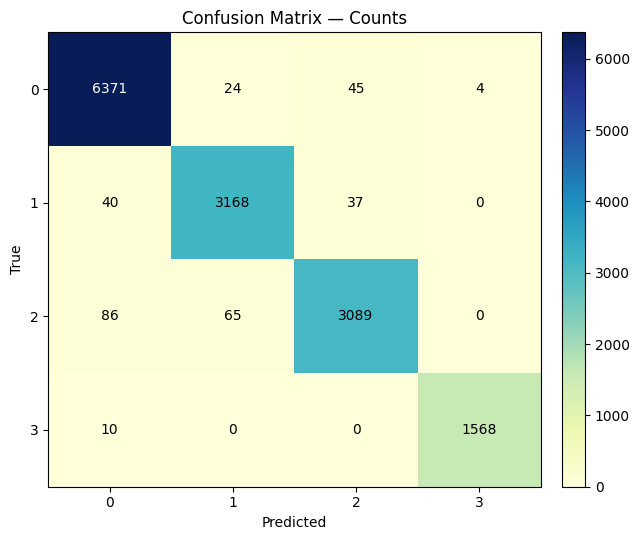

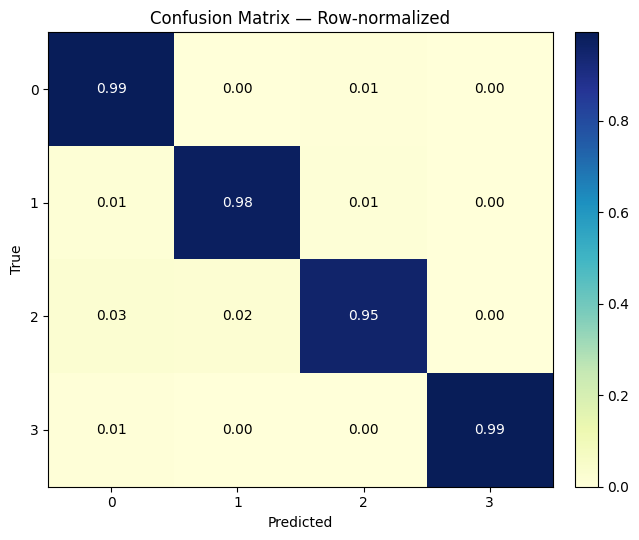

In [10]:
# ---------- Confusion Matrix (pretty plot) ----------
def plot_confusion_matrix(cm, classes, normalize=False, title="Confusion Matrix"):
    if normalize:
        cm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    
    
    im = ax.imshow(cm, interpolation="nearest", aspect="auto", cmap="YlGnBu")
    
    plt.title(title)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    tick_marks = np.arange(len(classes))
    ax.set_xticks(tick_marks); ax.set_yticks(tick_marks)
    ax.set_xticklabels(classes); ax.set_yticklabels(classes)
    plt.xlabel("Predicted"); plt.ylabel("True")

    thresh = cm.max() / 2.0 if cm.size else 0.5
    fmt = ".2f" if normalize else "d"
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    return fig

cm = confusion_matrix(y_test, y_pred, labels=classes)
print("\n[TEST] Confusion Matrix (rows=true, cols=pred):\n", cm)
_ = plot_confusion_matrix(cm, classes=classes, normalize=False, title="Confusion Matrix — Counts")
plt.show()
_ = plot_confusion_matrix(cm, classes=classes, normalize=True, title="Confusion Matrix — Row-normalized")
plt.show()

In [11]:
# ---------- Helper: TPR at fixed FPR ----------
def tpr_at_fixed_fpr(fpr, tpr, target_fpr: float) -> float:
    
    fpr = np.asarray(fpr); tpr = np.asarray(tpr)
    mask = fpr <= target_fpr
    if not np.any(mask):  
        idx = np.argmin(fpr)
        return float(tpr[idx])
    return float(np.max(tpr[mask]))

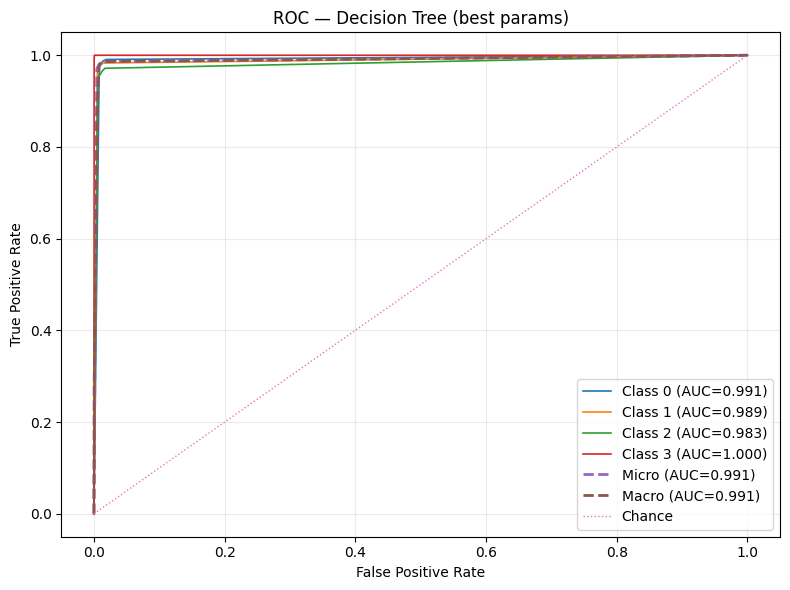

[ROC] TPR at FPR=1%  |  class 0 TPR@FPR=1% = 0.9814  |  class 1 TPR@FPR=1% = 0.9781  |  class 2 TPR@FPR=1% = 0.9528  |  class 3 TPR@FPR=1% = 1.0000  |  micro=0.9816
[ROC] TPR at FPR=5%  |  class 0 TPR@FPR=5% = 0.9908  |  class 1 TPR@FPR=5% = 0.9831  |  class 2 TPR@FPR=5% = 0.9716  |  class 3 TPR@FPR=5% = 1.0000  |  micro=0.9858


In [12]:
# ---------- ROC (OvR) ----------
if hasattr(best_clf, "predict_proba"):
    y_score = best_clf.predict_proba(X_test)
    if isinstance(y_score, list):  
        y_score = np.column_stack([p[:, 1] for p in y_score])

    y_bin = label_binarize(y_test, classes=classes)
    if y_bin.ndim == 1:  # binary fallback
        y_bin = np.column_stack([1 - y_bin, y_bin])

    # Align columns if class order differs
    if y_score.shape[1] != y_bin.shape[1]:
        aligned = np.zeros((y_score.shape[0], y_bin.shape[1]))
        for j, cls in enumerate(best_clf.classes_):
            idx = np.where(classes == cls)[0][0]
            aligned[:, idx] = y_score[:, j]
        y_score = aligned

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(y_bin.shape[1]):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Micro/macro
    fpr["micro"], tpr["micro"], _ = roc_curve(y_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(y_bin.shape[1])]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(y_bin.shape[1]):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= y_bin.shape[1]
    fpr["macro"], tpr["macro"] = all_fpr, mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    # Plot ROC
    plt.figure(figsize=(8, 6))
    for i, cls in enumerate(classes):
        plt.plot(fpr[i], tpr[i], lw=1.2, label=f"Class {cls} (AUC={roc_auc[i]:.3f})")
    plt.plot(fpr["micro"], tpr["micro"], lw=2, linestyle="--", label=f"Micro (AUC={roc_auc['micro']:.3f})")
    plt.plot(fpr["macro"], tpr["macro"], lw=2, linestyle="--", label=f"Macro (AUC={roc_auc['macro']:.3f})")
    plt.plot([0, 1], [0, 1], lw=1, linestyle=":", label="Chance")
    plt.title("ROC — Decision Tree (best params)")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right"); plt.grid(alpha=0.25); plt.tight_layout()
    plt.show()

    # TPR @ fixed FPRs
    for tg in [0.01, 0.05]:
        lines = []
        for i, cls in enumerate(classes):
            tpr_fixed = tpr_at_fixed_fpr(fpr[i], tpr[i], tg)
            lines.append(f"class {cls} TPR@FPR={tg*100:.0f}% = {tpr_fixed:.4f}")
        tpr_micro = tpr_at_fixed_fpr(fpr["micro"], tpr["micro"], tg)
        print(f"[ROC] TPR at FPR={tg*100:.0f}%  |  " + "  |  ".join(lines) + f"  |  micro={tpr_micro:.4f}")


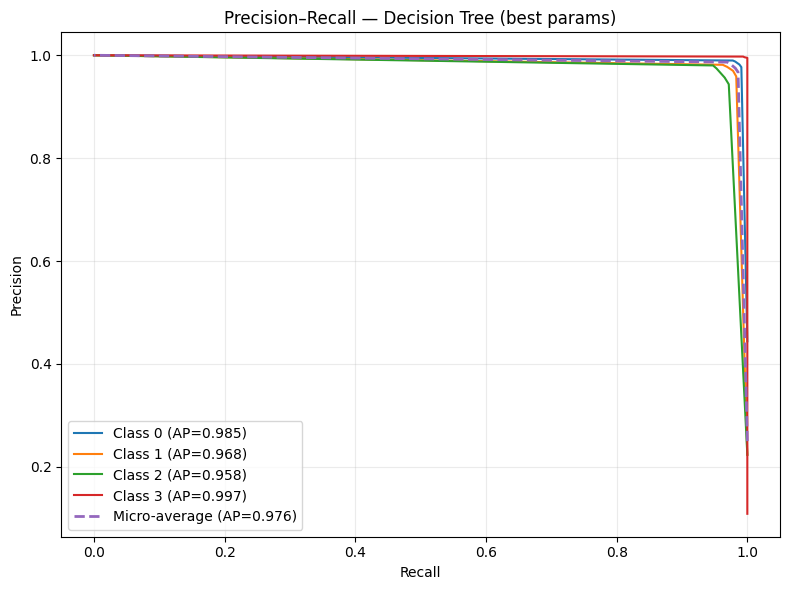

In [13]:
# ---------- Precision–Recall curves (+ AP) ----------

if hasattr(best_clf, "predict_proba"):
    # y_bin, y_score already built above
    # Per-class PR + AP
    plt.figure(figsize=(8, 6))
    ap_scores = {}
    for i, cls in enumerate(classes):
        precision, recall, _ = precision_recall_curve(y_bin[:, i], y_score[:, i])
        ap = average_precision_score(y_bin[:, i], y_score[:, i])
        ap_scores[cls] = ap
        plt.plot(recall, precision, lw=1.5, label=f"Class {cls} (AP={ap:.3f})")
    # Micro-average PR
    precision_micro, recall_micro, _ = precision_recall_curve(y_bin.ravel(), y_score.ravel())
    ap_micro = average_precision_score(y_bin.ravel(), y_score.ravel())
    plt.plot(recall_micro, precision_micro, lw=2, linestyle="--", label=f"Micro-average (AP={ap_micro:.3f})")
    plt.title("Precision–Recall — Decision Tree (best params)")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.legend(loc="best"); plt.grid(alpha=0.25); plt.tight_layout()
    plt.show()

In [14]:
# ---------- Save the trained best model ----------
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_filename = (
    f"decision_tree_best_with_f1_with_light_colored_cm{study.best_params.get('criterion','?')}"
    f"_d{study.best_params.get('max_depth','None')}_{stamp}.pkl"
)
save_path = os.path.join(OUT_DIR, model_filename)
joblib.dump(best_clf, save_path)
print(f"\n[INFO] Saved model to: {os.path.abspath(save_path)}")
print(f"[MODEL] depth={best_clf.get_depth()}  leaves={best_clf.get_n_leaves()}")


[INFO] Saved model to: /home/ubuntu1/projects/MPhilCodes/best_model_trained_after_parameter_tuning/decision_tree_best_with_f1_with_light_colored_cmgini_d40_20251014_161708.pkl
[MODEL] depth=27  leaves=1182
